# Ajuste dos canais e da atenção da PGANN

A PGANN reutiliza os blocos convolucionais da PGNN e preserva o latente espacial, sem camada totalmente conectada. Do latente partem dois caminhos: o decodificador principal completo e um caminho separado de três blocos para as características dos operadores de atenção. As três saídas ponderadas são redimensionadas e concatenadas à saída totalmente decodificada antes da convolução final, sigmoide e escalonamento.

Com as escalas de canais em 1, o codificador dobra os canais por bloco e o decodificador reduz os canais latentes pela metade por bloco. Para 22 canais de entrada, cinco blocos de codificação e quatro de decodificação, o codificador tem 44, 88, 176, 352 e 704 canais. O decodificador principal usa 352, 176, 88 e 44 canais. O caminho separado da atenção usa os três primeiros valores: 352, 176 e 88 canais, com pesos próprios. O artigo mostra os caminhos, mas não especifica suas larguras nem se os pesos são compartilhados. Os kernels, a redução das projeções e o eixo espacial do Softmax também são escolhas locais.

As listas em SEARCH_VALUES definem exatamente os candidatos pesquisados. Uma lista com um único valor fixa esse parâmetro. Os números de blocos permanecem na configuração-base. A escala do codificador multiplica suas larguras originais. A escala do decodificador multiplica cada largura obtida por divisão inteira dos canais latentes por potências de dois. O arredondamento usa round, com mínimo de um canal. Os kernels devem ser inteiros positivos ímpares e a redução deve ser um inteiro positivo. A configuração-base preserva a implementação original com escalas 1, kernels 1 e redução 2. Ao alterar os candidatos, use outro STUDY_VERSION.

A busca usa as amostras 0 e 1 do Marmousi por 500 épocas. Como essas amostras orientam a seleção da configuração, o resultado não mede generalização para modelos de velocidade não vistos.

As saídas salvas abaixo são históricas e não correspondem à configuração atual com caminho separado de atenção. O novo nome do estudo separa esta arquitetura das execuções anteriores.

In [1]:
from tuning.optuna import (
    create_or_load_study,
    display_trials,
    export_best_trial_params,
    plot_optimization_history,
    plot_param_importances,
    print_search_ranges,
    run_optuna_study,
    setup_optuna_notebook,
)

In [2]:
MODEL_TYPE = "pgann_mardan_2024"
VALIDATION_DATASET_NAMES = ["Marmousi"]
SAMPLE_INDICES = [0, 1]
DATASETS_ROOT = None  # Defina quando os dados estiverem fora do repositório.
MAX_TRIALS = 100
SEARCH_SEED = 24
OBJECTIVE_METRIC = "model_loss"
OBJECTIVE_AGGREGATE = "mean_last_10"

# Edite estas listas para definir os números pesquisados pelo Optuna.
SEARCH_VALUES = {
    "pgann_encoder_channel_scale": [0.5, 0.75, 1.0],
    "pgann_decoder_channel_scale": [0.5, 0.75, 1.0],
    "pgann_attention_latent_kernel_size": [1, 3, 5],
    "pgann_attention_feature_kernel_size": [1, 3, 5],
    "pgann_attention_score_kernel_size": [1, 3, 5],
    "pgann_attention_reduction": [1, 2, 4, 8],
}
# Use outro nome ao alterar os candidatos para separar os estudos.
STUDY_VERSION = "marmousi500_pgann_separate_v12"
optuna_config = setup_optuna_notebook(
    MODEL_TYPE,
    validation_dataset_names=VALIDATION_DATASET_NAMES,
    search_params=list(SEARCH_VALUES),
    categorical_values=SEARCH_VALUES,
    max_trials=MAX_TRIALS,
    search_seed=SEARCH_SEED,
    objective_metric=OBJECTIVE_METRIC,
    objective_aggregate=OBJECTIVE_AGGREGATE,
    sample_indices=SAMPLE_INDICES,
    datasets_root=DATASETS_ROOT,
    optuna_study_version=STUDY_VERSION,
)

tipo de modelo:         pgann_mardan_2024
caminho da configuração: config/models/pgann_mardan_2024_config.json
dispositivo:             cuda
datasets de validação:   Marmousi
épocas de busca:         500
máximo de testes:        100


## Espaço de busca

In [3]:
print_search_ranges(optuna_config)

Parâmetros pesquisados: ['pgann_encoder_channel_scale', 'pgann_decoder_channel_scale', 'pgann_attention_latent_kernel_size', 'pgann_attention_feature_kernel_size', 'pgann_attention_score_kernel_size', 'pgann_attention_reduction']
  pgann_encoder_channel_scale: [0.5, 0.75, 1.0]
  pgann_decoder_channel_scale: [0.5, 0.75, 1.0]
  pgann_attention_latent_kernel_size: [1, 3, 5]
  pgann_attention_feature_kernel_size: [1, 3, 5]
  pgann_attention_score_kernel_size: [1, 3, 5]
  pgann_attention_reduction: [1, 2, 4, 8]
Configuração base/fixa: {"adam_betas": [0.5, 0.9], "checkpoint_time_steps": 10, "epochs": 500, "final_out_channels": 1, "gradient_clip_norm": 1.0, "learning_rate": 0.001, "loss_filter_order": 3, "loss_filter_padding": 512, "loss_filter_sample_rate_hz": 800, "loss_frequency_cutoffs_hz": [12, 25, 60], "lr_gamma": 0.5, "lr_milestone": 120, "model_output_max": 1.0, "model_output_min": 0.0, "n_blocks_decoder": 4, "n_blocks_encoder": 5, "pgann_attention_feature_kernel_size": 1, "pgann_atte

## Estudo

In [4]:
study, remaining_trials = create_or_load_study(optuna_config)

[I 2026-10-22 18:30:35,734] Using an existing study with name 'pgann_mardan_2024_marmousi_500_Marmousi_marmousi500_pgann_separate_v12' instead of creating a new one.


O estudo já possui 49 teste(s); o baseline não será colocado na fila novamente.
nome do estudo:        pgann_mardan_2024_marmousi_500_Marmousi_marmousi500_pgann_separate_v12
armazenamento:         sqlite:////home/caiopinho/projects/tcc-fwi/results/hyperparameter_search/pgann_mardan_2024_marmousi_optuna_500_fixed.db
testes existentes:     49
testes finalizados:    49
testes restantes:      51
orçamento de épocas:
  por teste:          500 épocas
  total planejado:    50,000 épocas
  concluídas/executadas: 13,300 épocas (26.60% do total)
  não executadas:     11,200 épocas (45.71% dos testes finalizados, 22.40% do total)
  testes restantes:   51
  melhor restante:    5,100 épocas
  estimativa restante: 13,843 épocas
  pior restante:      25,500 épocas
  tempo médio/época:  2.15s
  melhor caso:        3h 03m 03s
  tempo estimado:     8h 16m 51s
  pior caso:          15h 15m 14s


## Execução

In [5]:
run_optuna_study(optuna_config, study, remaining_trials)

  0%|          | 0/51 [00:00<?, ?it/s]

{
  "model": {
    "pgann_attention_feature_kernel_size": 1,
    "pgann_attention_latent_kernel_size": 5,
    "pgann_attention_reduction": 8,
    "pgann_attention_score_kernel_size": 3,
    "pgann_decoder_channel_scale": 0.75,
    "pgann_encoder_channel_scale": 1.0
  },
  "training": {}
}
Teste Optuna 0049 | modelo: pgann_mardan_2024 | dataset: Marmousi | amostra: 0
[I 2026-10-22 18:34:16,776] Trial 49 pruned. Podado na época 100 com model_loss=171.262659 (média_móvel_10)
orçamento de épocas:
  por teste:          500 épocas
  total planejado:    50,000 épocas
  concluídas/executadas: 13,400 épocas (26.80% do total)
  não executadas:     11,600 épocas (46.40% dos testes finalizados, 23.20% do total)
  testes restantes:   50
  melhor restante:    5,000 épocas
  estimativa restante: 13,400 épocas
  pior restante:      25,000 épocas
  tempo médio/época:  2.15s
  melhor caso:        2h 59m 28s
  tempo estimado:     8h 00m 58s
  pior caso:          14h 57m 20s
{
  "model": {
    "pgann_atte

## Tentativas

In [6]:
display_trials(study)

,number,value,datetime_start,datetime_complete,duration,params_pgann_attention_feature_kernel_size,params_pgann_attention_latent_kernel_size,params_pgann_attention_reduction,params_pgann_attention_score_kernel_size,params_pgann_decoder_channel_scale,...,user_attrs_Marmousi_s0001_objective_epoch,user_attrs_Marmousi_s0001_objective_model_loss,user_attrs_optuna_epoch_time_seconds,user_attrs_optuna_epochs_completed,user_attrs_optuna_planned_epochs,user_attrs_optuna_pruned_epochs,user_attrs_selection_split,user_attrs_validation_dataset_names,system_attrs_fixed_params,state
40,40,74.096568,2026-10-22 17:01:23.785077,2026-10-22 17:23:36.483402,0 days 00:22:12.698325,1,5,8,3,0.50,...,500.0,75.876945,1320.131138,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
16,16,74.711505,2026-10-22 14:26:02.464020,2026-10-22 14:47:03.678010,0 days 00:21:01.213990,3,1,2,1,0.50,...,500.0,75.173001,1250.957811,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
38,38,74.873130,2026-10-22 16:36:43.521863,2026-10-22 16:59:20.187442,0 days 00:22:36.665579,1,5,8,3,0.50,...,500.0,75.975077,1344.021979,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
72,72,74.874810,2026-10-22 19:57:12.047841,2026-10-22 20:17:22.039665,0 days 00:20:09.991824,3,1,8,1,0.50,...,500.0,76.513435,1200.233702,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
22,22,75.001056,2026-10-22 15:19:41.733506,2026-10-22 15:40:18.451781,0 days 00:20:36.718275,3,1,8,1,0.50,...,500.0,75.545290,1226.565575,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
83,83,76.041883,2026-10-22 20:36:45.580891,2026-10-22 20:56:46.120713,0 days 00:20:00.539822,3,1,8,1,0.50,...,500.0,76.517552,1190.774303,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
41,41,76.516757,2026-10-22 17:23:36.626275,2026-10-22 17:44:50.980739,0 days 00:21:14.354464,1,5,8,3,0.50,...,500.0,79.364858,1262.152453,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
93,93,76.530349,2026-10-22 21:17:04.092447,2026-10-22 21:36:47.314059,0 days 00:19:43.221612,3,1,8,1,0.50,...,500.0,78.894100,1173.473279,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
20,20,76.574752,2026-10-22 14:58:05.624076,2026-10-22 15:17:43.991445,0 days 00:19:38.367369,3,1,8,1,0.50,...,500.0,74.759462,1168.685362,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE
14,14,76.757535,2026-10-22 14:04:19.546490,2026-10-22 14:24:16.242005,0 days 00:19:56.695515,3,1,2,1,0.50,...,500.0,76.361828,1186.916122,1000.0,1000.0,0.0,validation,[Marmousi],NaN,COMPLETE


## Importância do parâmetro e histórico

[I 2026-10-22 21:57:05,897] A new study created in memory with name: no-name-d4c15a54-7e69-44fa-aaea-f25f0af7e74a
/home/caiopinho/projects/tcc-fwi/tuning/optuna/notebook.py:644: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna_viz.plot_param_importances(_study_without_failed_trials(study))


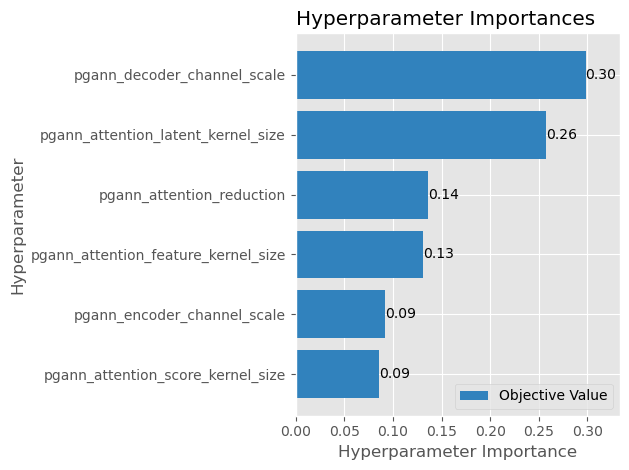

[I 2026-10-22 21:57:06,563] A new study created in memory with name: no-name-db68180e-2920-44b0-b947-89e4aaf83dce
/home/caiopinho/projects/tcc-fwi/tuning/optuna/notebook.py:660: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna_viz.plot_optimization_history(_study_without_failed_trials(study))


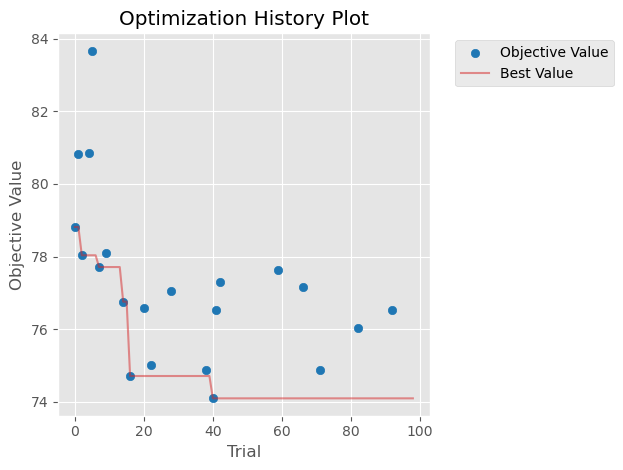

In [7]:
plot_param_importances(optuna_config, study)
plot_optimization_history(optuna_config, study)

## Exportação

In [8]:
export_best_trial_params(optuna_config, study)

Salvo em: /home/caiopinho/projects/tcc-fwi/results/hyperparameter_search/pgann_mardan_2024_marmousi_optuna_500_fixed_marmousi500_pgann_separate_v12_best_params.json

Melhor teste do Optuna:
  número do teste:  40
  valor:             74.09656762684186
  épocas:            500

JSON dos melhores parâmetros:
{
  "adam_betas": [
    0.5,
    0.9
  ],
  "best_trial_number": 40,
  "best_trial_value": 74.09656762684186,
  "checkpoint_time_steps": 10,
  "epochs": 500,
  "final_out_channels": 1,
  "gradient_clip_norm": 1.0,
  "learning_rate": 0.001,
  "loss_filter_order": 3,
  "loss_filter_padding": 512,
  "loss_filter_sample_rate_hz": 800,
  "loss_frequency_cutoffs_hz": [
    12,
    25,
    60
  ],
  "lr_gamma": 0.5,
  "lr_milestone": 120,
  "model_output_max": 1.0,
  "model_output_min": 0.0,
  "n_blocks_decoder": 4,
  "n_blocks_encoder": 5,
  "note": "A sele\u00e7\u00e3o do Optuna usa a valida\u00e7\u00e3o agregada model_loss; avalie a configura\u00e7\u00e3o congelada uma vez no conjunto de